In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

data_path = os.path.join('..', 'data', 'processed', 'master_gaming_dataset.csv')
df = pd.read_csv(data_path)

df_clean = df.dropna(subset=['release_year', 'Estimated_Revenue_USD']).copy()
df_clean['release_year'] = df_clean['release_year'].astype(int)


In [18]:
df_filtered = df_clean[df_clean['release_year'].between(2010, 2024)]
df_yearly = df_filtered.groupby(['release_year', 'Platform_Category'])['Estimated_Revenue_USD'].sum().unstack(fill_value = 0) / 1_000_000

df_yearly['Total_Rev'] = df_yearly.sum(axis=1)
print(df_yearly)

columns = ['PC','Console','Mobile']
comparison = []
for col in columns:
    data = df_yearly[col].dropna()

    x = data.index.values.reshape(-1, 1)
    y = data.values

    n = len(data)
    train_index = int(n * 0.8)

    x_train = x[:train_index]
    y_train = y[:train_index]

    x_test = x[train_index:]
    y_test = y[train_index:]
    
    linear_model = LinearRegression()
    linear_model.fit(x_train, y_train)

    linear_pred = linear_model.predict(x_test)
    linear_mae = mean_absolute_error(y_test, linear_pred)
    linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
    comparison.append({
        'Platform': col,
        'Model': 'Linear_Trend',
        'MAE': linear_mae,
        'RMSE': linear_rmse
    })
    naive_pred = np.repeat(y_train[-1], len(y_test))
    naive_mae = mean_absolute_error(y_test, naive_pred)
    naive_rmse = np.sqrt(mean_squared_error(y_test, naive_pred))
    comparison.append({
        'Platform': col,
        'Model': 'Naive',
        'MAE': naive_mae,
        'RMSE': naive_rmse
    })
comparison_df = pd.DataFrame(comparison)

print(comparison_df)

Platform_Category  Console        Mobile           PC     Total_Rev
release_year                                                       
2010               26433.6   1351.936808   3805.13815  31590.674958
2011               24636.0   3878.401332   5920.04700  34434.448332
2012               16540.2  11440.987262   8957.73640  36938.923662
2013               15655.8  30901.289443  11442.78530  57999.874743
2014               16867.2  31592.280837  11571.39520  60030.876037
2015               13516.8  24190.364187  20858.29160  58565.455787
2016               12093.6  45720.151076  19175.21105  76988.962126
2017               11425.8  49786.684956  19658.75705  80871.242006
2018                8793.6  36561.566676  18145.23490  63500.401576
2019               27030.0  31905.415418  16253.13255  75188.547968
2020               23883.6  33376.889140  22567.24010  79827.729239
2021               17467.8  27246.527029  21920.19200  66634.519029
2022               17242.4  22343.113802  22878.

In [19]:
# console, mobile và total_rev => Naive
# pc => linear_trend
best_models = comparison_df.loc[comparison_df.groupby('Platform')['MAE'].idxmin()].reset_index(drop=True)

future_years = np.arange(2025, 2031)
forecast_rows = []

for platform in columns:

    data = df_yearly[platform].dropna()

    X_all = data.index.values.reshape(-1, 1)
    y_all = data.values

    X_future = future_years.reshape(-1, 1)

    selected_model = best_models.loc[best_models['Platform'] == platform, 'Model'].iloc[0]

    print(platform, selected_model)

    if selected_model == 'Linear_Trend':
        model = LinearRegression()
        model.fit(X_all, y_all)

        predictions = model.predict(X_future)

        fitted_values = model.predict(X_all)
        residuals = y_all - fitted_values

        residual_std = np.std(residuals, ddof=1)

        n = len(y_all)
        x_mean = X_all.mean()

        sxx = np.sum((X_all.flatten() - x_mean) ** 2)
        standard_error = residual_std * np.sqrt(
            1
            + 1 / n
            + ((future_years - x_mean) ** 2 / sxx)
        )

    elif selected_model == 'Naive':

        predictions = np.repeat(y_all[-1], len(future_years))
        changes = np.diff(y_all)
        residual_std = np.std(changes, ddof=1)
        horizon = np.arange(1, len(future_years) + 1)
        standard_error = residual_std * np.sqrt(horizon)

    elif selected_model == 'Naive_Drift':
        average_change = np.mean(np.diff(y_all))
        horizon = np.arange(1, len(future_years) + 1)
        predictions = (y_all[-1] + average_change * horizon)
        changes = np.diff(y_all)
        residual_std = np.std(changes, ddof=1)
        standard_error = residual_std * np.sqrt(horizon)

    lower_bound = predictions - 1.96 * standard_error
    upper_bound = predictions + 1.96 * standard_error
    predictions = np.maximum(predictions, 0)
    lower_bound = np.maximum(lower_bound, 0)
    upper_bound = np.maximum(upper_bound, 0)

    for year, pred, lower, upper in zip(future_years, predictions,lower_bound, upper_bound):
        forecast_rows.append({
            'year': year,
            'platform': platform,
            'model': selected_model,
            'forecast_revenue_Mil_USD': pred,
            'lower_95_Mil_USD': lower,
            'upper_95_Mil_USD': upper
        })

forecast_platform = pd.DataFrame(
    forecast_rows
)
forecast_total = forecast_platform.groupby('year', as_index=False).agg({
        'forecast_revenue_Mil_USD': 'sum',
        'lower_95_Mil_USD': 'sum',
        'upper_95_Mil_USD': 'sum'
    })

forecast_total['platform'] = 'Total_Rev'
print(forecast_platform)

PC Linear_Trend
Console Naive
Mobile Naive
    year platform         model  forecast_revenue_Mil_USD  lower_95_Mil_USD  \
0   2025       PC  Linear_Trend              28402.612539      20915.767499   
1   2026       PC  Linear_Trend              29842.964276      22182.655801   
2   2027       PC  Linear_Trend              31283.316013      23433.671551   
3   2028       PC  Linear_Trend              32723.667751      24669.934119   
4   2029       PC  Linear_Trend              34164.019488      25892.535485   
5   2030       PC  Linear_Trend              35604.371225      27102.525261   
6   2025  Console         Naive              11317.600000          0.000000   
7   2026  Console         Naive              11317.600000          0.000000   
8   2027  Console         Naive              11317.600000          0.000000   
9   2028  Console         Naive              11317.600000          0.000000   
10  2029  Console         Naive              11317.600000          0.000000   
11  2030 

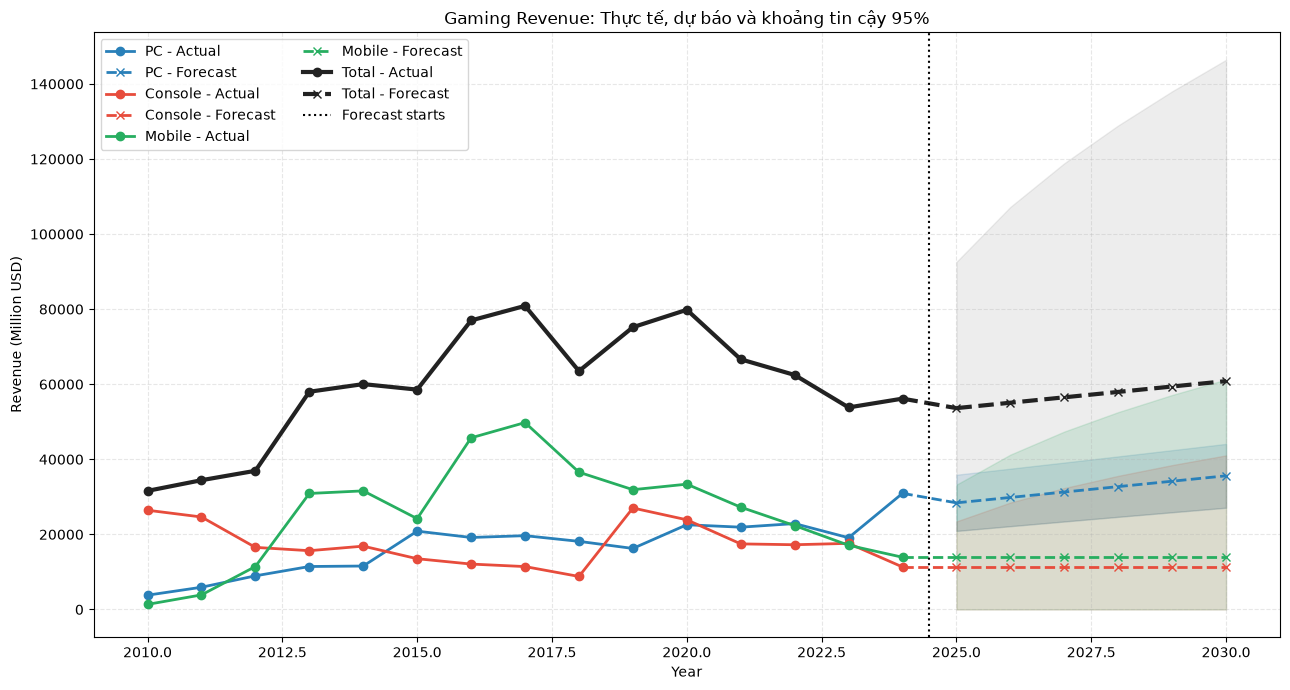

In [20]:
plt.figure(figsize=(13, 7))
colors = {
    'PC': '#2980b9',
    'Console': '#e74c3c',
    'Mobile': '#27ae60', 
    'Total_Rev': '#222222'

}
for platform in ['PC', 'Console', 'Mobile']:
    actual = df_yearly[platform]
    forecast = forecast_platform[forecast_platform['platform'] == platform]
    color = colors[platform]

    plt.plot(
        actual.index,
        actual.values,
        marker='o',
        linewidth=2,
        color = color,
        label=f'{platform} - Actual'
    )
    plt.plot(
        forecast['year'],
        forecast['forecast_revenue_Mil_USD'],
        marker='x',
        linestyle='--',
        linewidth=2,
        color = color,
        label=f'{platform} - Forecast'
    )
    plt.plot(
    [
        actual.index[-1],
        forecast['year'].iloc[0]
    ],
    [
        actual.iloc[-1],
        forecast['forecast_revenue_Mil_USD'].iloc[0]
    ],
    linestyle='--',
    linewidth=2,
    color=color)
    plt.fill_between(
        forecast['year'],
        forecast['lower_95_Mil_USD'],
        forecast['upper_95_Mil_USD'],
        color= color,
        alpha=0.15
    )
actual_total = df_yearly['Total_Rev'].dropna()

# Total thực tế
plt.plot(
    actual_total.index,
    actual_total.values,
    color=colors['Total_Rev'],
    marker='o',
    linewidth=3,
    label='Total - Actual'
)

# Total dự báo
plt.plot(
    forecast_total['year'],
    forecast_total['forecast_revenue_Mil_USD'],
    color=colors['Total_Rev'],
    marker='x',
    linestyle='--',
    linewidth=3,
    label='Total - Forecast'
)

plt.plot(
    [
        actual_total.index[-1],
        forecast_total['year'].iloc[0]
    ],
    [
        actual_total.iloc[-1],
        forecast_total[
            'forecast_revenue_Mil_USD'
        ].iloc[0]
    ],
    linestyle='--',
    linewidth=3,
    color='#222222'
)

# Khoảng dự báo Total
plt.fill_between(
    forecast_total['year'].values,
    forecast_total['lower_95_Mil_USD'].values,
    forecast_total['upper_95_Mil_USD'].values,
    color=colors['Total_Rev'],
    alpha=0.08
)

# Đường phân cách actual/forecast
plt.axvline(
    x=2024.5,
    color='black',
    linestyle=':',
    linewidth=1.5,
    label='Forecast starts'
)
plt.title('Gaming Revenue: Thực tế, dự báo và khoảng tin cậy 95%')
plt.xlabel('Year')
plt.ylabel('Revenue (Million USD)')
plt.grid(alpha=0.3, linestyle='--')
plt.legend(ncol=2)
plt.tight_layout()
plt.show()